<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week11/Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS11 - Klasifikasi 2**<hr>
# **Praktikum 2: Klasifikasi SVM dengan Data Dummy Non-Linier**<hr>

## **Langkah 1 - Ilustrasi Data Non-Linier**
### **Langkah 1a - Import Library**

In [1]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

### **Langkah 1b - Buat Kembali Fungsi Plotting**

In [2]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

### **Langkah 1c - Buat Data Dummy Non-Linier**

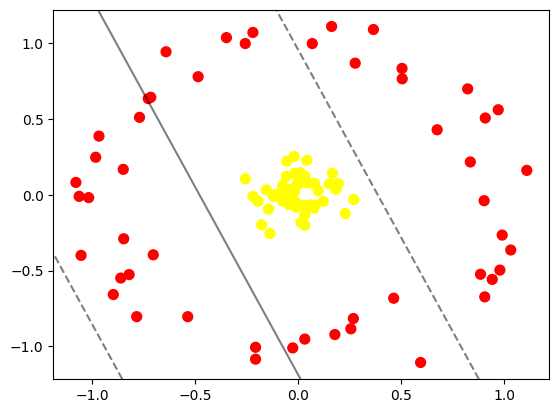

In [3]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

**Berdasarkan contoh data di atas, tidak ditemukan sebuah garis pemisah linier yang mampu berperan sebagai pemisah data. Oleh karena itu, proyeksi (sudut pandang) lain terhadap data diperlukan supaya data dapat terpisahkan dengan jelas. Pada kegiatan ini, proyeksi yang digunakan adalah proyeksi berbasis radial.**

**Karena proyeksi radial tidak cukup menggunakan model 2D, maka plot visualisasi diubah menjadi model 3D.**

In [4]:
r = np.exp(-(X ** 2).sum(1))

In [5]:
	from mpl_toolkits import mplot3d
	from ipywidgets import interact, fixed

	def plot_3D(elev=30, azim=30, X=X, y=y):
	    ax = plt.subplot(projection='3d')
	    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
	    ax.view_init(elev=elev, azim=azim)
	    ax.set_xlabel('x')
	    ax.set_ylabel('y')
	    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.10857734,  0.00381701],
       [-0.8460888 , -0.28946433],
       [-0.01829379,  0.1413605 ],
       [ 0.90759111,  0.507755  ],
       [ 1.03111282, -0.36357311],
       [ 0.04209906,  0.22872886],
       [-1.05306089, -0.39910436],
       [ 0.0321788 ,  0.12254608],
       [-0.20661619, -1.00562423],
       [ 0.83495506,  0.2174565 ],
       [ 0.17810962, -0.92153884],
       [ 0.59391957, -1.10600177],
       [ 0.25552139, -0.88376983],
       [ 0.67410796,  0.43006636],
       [-0.70284542, -0.39531086],
       [ 0.50377045,  0.83488854],
       [-0.09415549, -0.00685089],
       [ 0.01432916, -0.18119095],
       [ 0.9019684 , -0.03824476],
       [-0.04440548,  0.01777507],
       [-0.14407028, -0.0929853 ],
       [ 0.36509608,  1.09184615],
       [ 0.03229532, -0.2005339 ],
       [-0.0551052 ,  0.22380509],
       [-0.01645885,  0.02336278],
       [-0.96610968,  0.38803373],
       [-0.7830898 , -0.80354549],
       [-0.76937996,  0.51205009],
       [-0.04473519, -0.06391102],
       [ 0.07573441, -0.08709655],
       [ 0.05987548, -0.06557229],
       [ 0.22832888, -0.12280442],
       [ 0.09653176,  0.0292894 ],
       [-0.1944498 , -0.04175868],
       [-1.07808826,  0.08247162],
       [-0.81992449, -0.52576828],
       [ 0.18393291,  0.03727926],
       [ 0.06268195, -0.07701629],
       [ 0.90503199, -0.6729709 ],
       [ 0.98964948, -0.26500402],
       [ 0.032118  , -0.95171843],
       [-0.07572166, -0.0410537 ],
       [ 0.46331643, -0.68192678],
       [-1.06217225, -0.00954585],
       [-0.48513889,  0.78034046],
       [ 0.12166098, -0.04267038],
       [ 0.82219385,  0.69995653],
       [ 0.06843255,  0.99902365],
       [ 0.1946453 ,  0.07595317],
       [-0.15471127,  0.03298143],
       [ 0.16596147,  0.14395791],
       [ 0.97042545,  0.56204874],
       [-0.20661773, -1.0841593 ],
       [-0.02041821,  0.25425198],
       [-0.01023804, -0.08112199],
       [-0.03498277, -0.03765234],
       [-0.13677982, -0.25502253],
       [-0.89660263, -0.65758621],
       [ 0.0798235 ,  0.07532389],
       [-0.00800085,  0.06072137],
       [ 0.02509959, -0.06937964],
       [ 0.26772927, -0.81583787],
       [-0.21954946,  1.07228505],
       [-0.03876155,  0.00597887],
       [ 0.50476519,  0.76636501],
       [ 0.88462095, -0.52387596],
       [-0.53555824, -0.80378471],
       [-1.01617458, -0.01786097],
       [ 0.03246507, -0.13316156],
       [ 0.94134773, -0.55761529],
       [-0.01432571, -0.04616789],
       [ 0.16226086,  1.11173063],
       [-0.21909426, -0.00949886],
       [-0.02619737, -1.00990452],
       [ 0.01100939,  0.14656432],
       [-0.2559888 ,  0.10636388],
       [-0.8484087 ,  0.16872653],
       [ 0.978415  , -0.49612102],
       [-0.12173469, -0.00664347],
       [-0.86039773, -0.54870177],
       [-0.72697625,  0.63557217],
       [ 1.10898727,  0.16189588],
       [-0.34782477,  1.03809393],
       [-0.17689769, -0.19694947],
       [ 0.00642665,  0.12053696],
       [-0.07555996,  0.05999778],
       [ 0.00867844,  0.0793454 ],
       [-0.98203362,  0.24851365],
       [-0.64087665,  0.94465847],
       [-0.11758844, -0.01163239],
       [-0.71483327,  0.64439605],
       [ 0.08056499, -0.06679945],
       [ 0.15136262,  0.07278661],
       [-0.05706502,  0.12180866],
       [-0.00502477,  0.07248317],
       [-0.25665887,  0.99911926],
       [ 0.26906363, -0.03016354],
       [-0.048892  ,  0.03635875],
       [ 0.27668117,  0.86960604],
       [ 0.04458894,  0.07875637]]), y=array([1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1]))>

## **Langkah 2 - Fitting Model**

In [8]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

**Plot hasil decision boundaries dari kernel RBF**

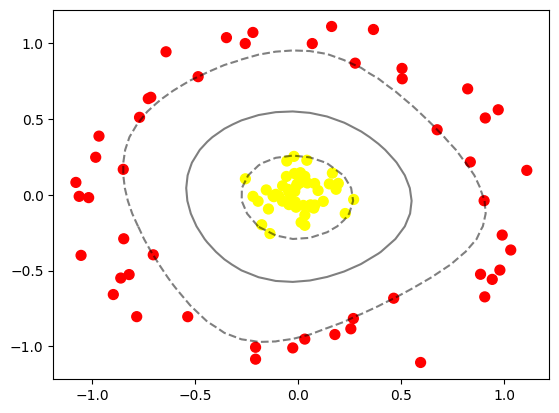

In [7]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')